In [ ]:
import warnings

import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

In [ ]:
from bank_churn_predictions.config import INTERIM_DATA_DIR
from bank_churn_predictions.dataset import load_raw_data

## Preprocessing

In [11]:
df = load_raw_data()
df

2026-10-09 17:00:02.403 | INFO     | bank_churn_predictions.dataset:load_raw_data:36 - Loading raw dataset from D:\Ravindu\Programming\My Roadmap\Phase 1\bank_churn_predictions\data\raw\Churn_Modelling.csv
2026-10-09 17:00:02.426 | INFO     | bank_churn_predictions.dataset:load_raw_data:40 - Loaded 10000 rows and 14 columns


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9995,9996,15606229,Obijiaku,771,France,Male,39,5,0.00,2,1,0,96270.64,0
9996,9997,15569892,Johnstone,516,France,Male,35,10,57369.61,1,1,1,101699.77,0
9997,9998,15584532,Liu,709,France,Female,36,7,0.00,1,0,1,42085.58,1
9998,9999,15682355,Sabbatini,772,Germany,Male,42,3,75075.31,2,1,0,92888.52,1


Duplicate rows: 0
Unique customer IDs: 10000


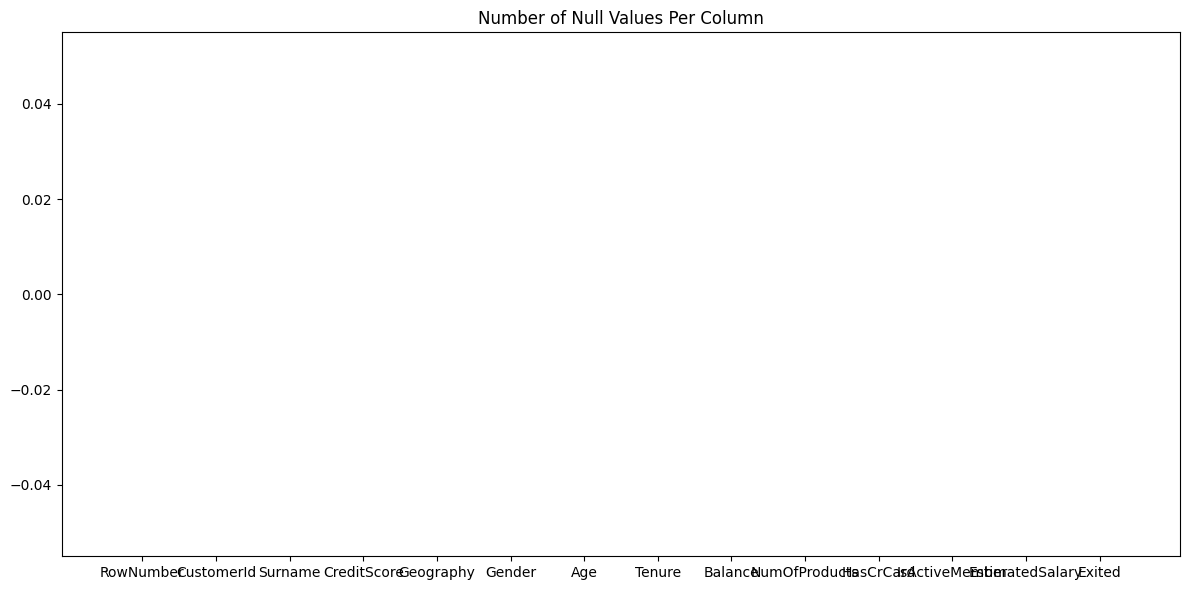

In [12]:
print("Duplicate rows:", df.duplicated().sum())
print("Unique customer IDs:", df["CustomerId"].nunique())

plt.figure(figsize=(12, 6))
plt.title("Number of Null Values Per Column")
plt.bar(df.columns, df.apply(lambda x: x.isna().sum()))
plt.tight_layout()

In [13]:
df.drop(
    ["RowNumber", "CustomerId", "Surname"], inplace=True, axis=1
)  # removed the columns that have no relevance to prediction

In [14]:
df.isna().sum()

CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [15]:
df.to_csv(INTERIM_DATA_DIR / "stage_1_preprocessing.csv", index=False)